In [1]:
import pandas as pd
import matplotlib.pyplot as plt

--- Step-by-Step LFSR Computation ---
 i  a_i  b_i  c_i (a_i ⊕ b_i)
 0    0    0                0
 1    1    1                0
 2    1    1                0
 3    0    0                0
 4    1    1                0
 5    1    1                0
 6    1    0                1
 7    0    1                1
 8    1    1                0
 9    1    0                1
10    1    1                0
11    0    1                1
12    1    0                1
13    1    1                0
14    1    1                0
15    0    0                0
16    1    1                0
17    1    1                0
18    1    0                1
19    0    1                1

--- Period Analysis ---
Sequence a_i pattern: [0] followed by repeating [1, 1, 0, 1] -> Period T_a = 4
Sequence b_i pattern: Repeating [0, 1, 1] -> Period T_b = 3
Theoretical combined period (LCM): lcm(4, 3) = 12
Actual resulting sequence c_i: [0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1]


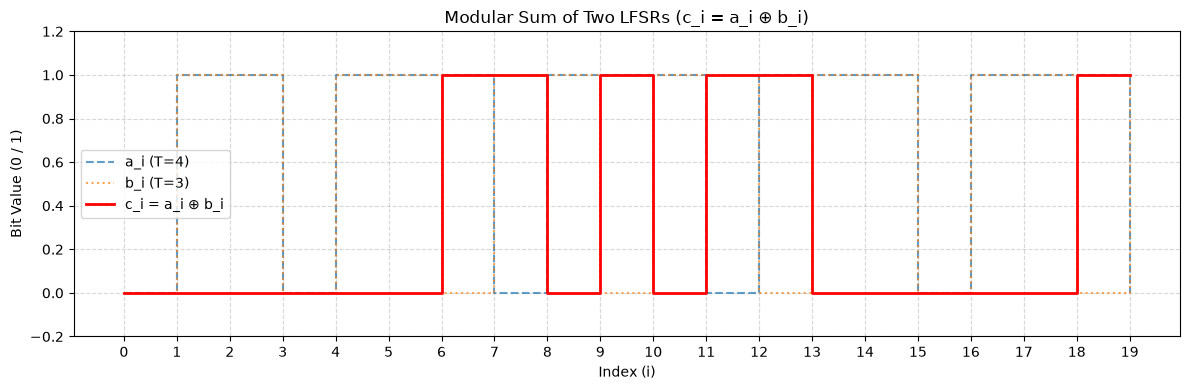

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

steps = 20

a = [0, 1, 1, 0, 1]

b = [0, 1]

for i in range(steps - 5):
    a.append(a[i + 1]) 

for i in range(steps - 2):
    b.append((b[i] + b[i + 1]) % 2) 

c = [a_val ^ b_val for a_val, b_val in zip(a, b)]

df = pd.DataFrame({"i": list(range(steps)), "a_i": a, "b_i": b, "c_i (a_i ⊕ b_i)": c})

print("--- Step-by-Step LFSR Computation ---")
print(df.to_string(index=False))

print("\n--- Period Analysis ---")
print("Sequence a_i pattern: [0] followed by repeating [1, 1, 0, 1] -> Period T_a = 4")
print("Sequence b_i pattern: Repeating [0, 1, 1] -> Period T_b = 3")
print("Theoretical combined period (LCM): lcm(4, 3) = 12")
print(f"Actual resulting sequence c_i: {c}")

plt.figure(figsize=(12, 4))
plt.step(range(steps), a, where="post", label="a_i (T=4)", linestyle="--", alpha=0.7)
plt.step(range(steps), b, where="post", label="b_i (T=3)", linestyle=":", alpha=0.7)
plt.step(range(steps), c, where="post", label="c_i = a_i ⊕ b_i", color="red", linewidth=2)

plt.title("Modular Sum of Two LFSRs (c_i = a_i ⊕ b_i)")
plt.xlabel("Index (i)")
plt.ylabel("Bit Value (0 / 1)")
plt.xticks(range(steps))
plt.ylim(-0.2, 1.2)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [3]:
def berlekamp_massey(sequence):
    N = len(sequence)
    C = [1]  # Connection polynomial
    B = [1]  # Copy of polynomial
    L = 0  # Current LFSR length
    m = 1  # Shifts counter
    b = 1  # Discrepancy from previous step

    print(
        f"{'N':<4} | {'s_N':<4} | {'d':<4} | {'L':<4} | {'Poly C(x)':<25} |"
        f" {'m':<4}"
    )
    print("-" * 60)

    for n in range(N):
        d = sequence[n]
        for i in range(1, L + 1):
            d ^= C[i] * sequence[n - i]

        if d == 0:
            m += 1
        else:
            T = list(C)
            padded_B = [0] * m + B
            max_len = max(len(C), len(padded_B))
            C = C + [0] * (max_len - len(C))
            for i in range(len(padded_B)):
                C[i] ^= padded_B[i]

            if 2 * L <= n:
                L = n + 1 - L
                B = T
                b = d
                m = 1
            else:
                m += 1

        poly_str = " + ".join(
            [f"x^{i}" if i > 0 else "1" for i, coef in enumerate(C) if coef == 1]
        )
        print(
            f"{n:<4} | {sequence[n]:<4} | {d:<4} | {L:<4} | {poly_str:<25} |"
            f" {m:<4}"
        )

    return L, C

c_seq = [0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1]

L_min, C_poly = berlekamp_massey(c_seq)

print("\n--- Berlekamp-Massey Result ---")
print(f"Minimal LFSR Length (Linear Complexity L): {L_min}")
print(
    "Minimal Polynomial C(x):",
    " + ".join(
        [f"x^{i}" if i > 0 else "1" for i, coef in enumerate(C_poly) if coef == 1]
    ),
)

N    | s_N  | d    | L    | Poly C(x)                 | m   
------------------------------------------------------------
0    | 0    | 0    | 0    | 1                         | 2   
1    | 0    | 0    | 0    | 1                         | 3   
2    | 0    | 0    | 0    | 1                         | 4   
3    | 0    | 0    | 0    | 1                         | 5   
4    | 0    | 0    | 0    | 1                         | 6   
5    | 0    | 0    | 0    | 1                         | 7   
6    | 1    | 1    | 7    | 1 + x^7                   | 1   
7    | 1    | 1    | 7    | 1 + x^1 + x^7             | 2   
8    | 0    | 1    | 7    | 1 + x^1 + x^2 + x^7       | 3   
9    | 1    | 0    | 7    | 1 + x^1 + x^2 + x^7       | 4   
10   | 0    | 1    | 7    | 1 + x^1 + x^2 + x^4 + x^7 | 5   
11   | 1    | 1    | 7    | 1 + x^1 + x^2 + x^4 + x^5 + x^7 | 6   
12   | 0    | 0    | 7    | 1 + x^1 + x^2 + x^4 + x^5 + x^7 | 7   
13   | 0    | 1    | 7    | 1 + x^1 + x^2 + x^4 + x^5 | 8   
14   | 0    

In [4]:
def berlekamp_massey(sequence):
    """Berlekamp-Massey algorithm over GF(2)"""
    N = len(sequence)
    C = [1]
    B = [1]
    L = 0
    m = 1
    b = 1

    for n in range(N):
        d = sequence[n]
        for i in range(1, L + 1):
            d ^= C[i] * sequence[n - i]

        if d == 0:
            m += 1
        else:
            T = list(C)
            padded_B = [0] * m + B
            max_len = max(len(C), len(padded_B))
            C = C + [0] * (max_len - len(C))
            for i in range(len(padded_B)):
                C[i] ^= padded_B[i]

            if 2 * L <= n:
                L = n + 1 - L
                B = T
                b = d
                m = 1
            else:
                m += 1
    return L, C


# --- 1. Inputs ---
ciphertext = bytes.fromhex(
    "5398eb7d7a2198e295f1e822a0e244e7c52d27010e425e3c4046212be3384fd4b7ee7b410b7ecd4d6e4d6986c51097c42366d41e1d"
)
known_plaintext = b"LFSR is not secure"
start_offset = 14  

cipher_bits = []
for b in ciphertext:
    cipher_bits.extend([(b >> (7 - i)) & 1 for i in range(8)])

known_pt_bits = []
for b in known_plaintext:
    known_pt_bits.extend([(b >> (7 - i)) & 1 for i in range(8)])

start_bit = start_offset * 8
known_gamma_bits = [
    c ^ p for c, p in zip(cipher_bits[start_bit:], known_pt_bits)
]

L, C_poly = berlekamp_massey(known_gamma_bits)

taps = [i for i, coef in enumerate(C_poly[1:], 1) if coef == 1]

print("--- LFSR Recovery Results ---")
print(f"Recovered LFSR Linear Complexity (L): {L} bits")
print(
    f"Connection Polynomial C(x): 1 + "
    + " + ".join([f"x^{t}" for t in taps])
)

full_gamma_bits = [0] * len(cipher_bits)

for i in range(len(known_gamma_bits)):
    full_gamma_bits[start_bit + i] = known_gamma_bits[i]

for i in range(start_bit + len(known_gamma_bits), len(cipher_bits)):
    fb = 0
    for tap in taps:
        fb ^= full_gamma_bits[i - tap]
    full_gamma_bits[i] = fb

for i in range(start_bit - 1, -1, -1):
    # c_i = sum(C_j * c_{i+j}) for j=1..L
    # c_{i} = fb ^ c_{i + max_tap} ...
    # From C(x): sum_{j=0}^L C_j * gamma_{k-j} = 0
    # Let k - max_tap = i  =>  gamma_i = sum_{j=0}^{max_tap-1} C_{max_tap - j} * gamma_{i + max_tap - j}
    max_tap = max(taps)
    fb = 0
    for tap in taps:
        if tap != max_tap:
            fb ^= full_gamma_bits[i + max_tap - tap]
    fb ^= full_gamma_bits[i + max_tap]
    full_gamma_bits[i] = fb

plaintext_bits = [c ^ g for c, g in zip(cipher_bits, full_gamma_bits)]

plaintext_bytes = bytearray()
for i in range(0, len(plaintext_bits), 8):
    byte_val = 0
    for b in plaintext_bits[i : i + 8]:
        byte_val = (byte_val << 1) | b
    plaintext_bytes.append(byte_val)

plaintext_str = plaintext_bytes.decode("ascii", errors="replace")

print("\n--- Decryption Result ---")
print(f"Decoded Plaintext:\n'{plaintext_str}'")

--- LFSR Recovery Results ---
Recovered LFSR Linear Complexity (L): 14 bits
Connection Polynomial C(x): 1 + x^1 + x^2 + x^3 + x^5 + x^6 + x^10 + x^12 + x^14

--- Decryption Result ---
Decoded Plaintext:
'�tream cipher LFSR is not secure because of linearity'


## Plaintext: Stream cipher LFSR is not secure because of linearity